In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys, json
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / 'figures').mkdir(exist_ok=True)
(ROOT / 'results').mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Python :', sys.executable)          # doit pointer vers le venv
print('Données disponibles :', *[p.name for p in sorted(RAW_DIR.glob('*.csv'))])

def save_dataset(df, name):
    path = PROCESSED_DIR / f'{name}.parquet'
    df.to_parquet(path, index=False)
    print('écrit :', path.name, df.shape)
    return path

def load_dataset(name):
    return pd.read_parquet(PROCESSED_DIR / f'{name}.parquet')

Python : /tmp/sparkvenv/bin/python
Données disponibles : adherents.csv emprunts.csv ouvrages.csv sites.csv


---
## 1. Contexte

**Origine.** Quatre tables d'un réseau de 11 sites de lecture publique : `emprunts` (table de faits, ~20 500 lignes, 2023-2024), `adherents` (2 650), `ouvrages` (420) et `sites` (11).

**Ce qu'elles décrivent.** Un emprunt relie un adhérent, un ouvrage et un site, avec une durée de prêt, un nombre de prolongations, la valeur de l'ouvrage, un mode (sur place, réservation en ligne, portage) et un statut (rendu, en retard, perdu).

**Question.** Où se concentrent les retards et les pertes, et pour quelle valeur ? Le jeu préparé doit permettre de le mesurer dans Power BI / Tableau (modèle en étoile) sans refaire de nettoyage.

In [2]:
raw = {name: pd.read_csv(RAW_DIR / f'{name}.csv') for name in ['emprunts', 'adherents', 'ouvrages', 'sites']}
for name, df in raw.items():
    print(f'{name:<10} {df.shape[0]:>6} lignes x {df.shape[1]} colonnes')
raw['emprunts'].head()

emprunts    20563 lignes x 10 colonnes
adherents    2650 lignes x 5 colonnes
ouvrages      420 lignes x 5 colonnes
sites          11 lignes x 5 colonnes


,id_emprunt,date_evenement,id_adherent,id_ouvrage,id_site,duree_pret_jours,nb_prolongations,valeur_ouvrage_eur,mode_emprunt,statut
0,EMP0017141,03/02/2024,ADH01040,OUV0150,SIT10,11.0,2,10.52,sur_place,rendu
1,EMP0001852,09/03/2023,ADH01907,OUV0027,SIT08,44.0,0,90.96,sur_place,rendu
2,EMP0009961,2023-06-21,ADH00282,OUV0108,SIT99,19.0,3,41.88,reservation_en_ligne,perdu
3,EMP0008711,20-03-2024,ADH02430,OUV0122,SIT02,17.0,2,45.38,portage,perdu
4,EMP0006209,2023-04-10,ADH00909,OUV0275,SIT02,24.0,3,12.32,reservation_en_ligne,rendu


---
## 2. Diagnostic

On applique `profile_dataframe` (séance 2), puis on **quantifie** chaque anomalie.

In [3]:
from exploration import profile_dataframe
for name, df in raw.items():
    print()
    profile_dataframe(df, name=name, verbose=False).pipe(lambda s: print(f'=== {name} : {len(df)} lignes, doublons stricts {df.duplicated().sum()}\n' + s.to_string()))


=== emprunts : 20563 lignes, doublons stricts 180
                      dtype  manquants  pct_manquants  cardinalite                                     exemples
id_emprunt              str          0           0.00        20383           EMP0017141, EMP0001852, EMP0009961
date_evenement          str        412           2.00         6820           03/02/2024, 09/03/2023, 2023-06-21
id_adherent             str          0           0.00         2600                 ADH01040, ADH01907, ADH00282
id_ouvrage              str          0           0.00          421                    OUV0150, OUV0027, OUV0108
id_site                 str          0           0.00           11                          SIT10, SIT08, SIT99
duree_pret_jours    float64       1841           8.95           92                             11.0, 44.0, 19.0
nb_prolongations      int64          0           0.00            4                                      2, 0, 3
valeur_ouvrage_eur      str          0           0.00

In [4]:
e, a, o, s = raw['emprunts'], raw['adherents'], raw['ouvrages'], raw['sites']
txt = lambda x: x.astype('string').str.strip().str.lower()
price_txt = e['valeur_ouvrage_eur'].astype('string').str.contains('EUR', na=False)
dates_txt = e['date_evenement'].astype('string')
pattern = dates_txt.str.replace(r'\d', '9', regex=True).str.replace(r'[A-Za-z]+', 'L', regex=True)
dup_ids_adh = a[a['id_adherent'].str.startswith('ADH99')]

anomalies = pd.DataFrame([
    ['Doublons stricts', 'emprunts (toutes)', int(e.duplicated().sum())],
    ['Casse / espaces', 'mode_emprunt, statut', int((e['mode_emprunt'] != txt(e['mode_emprunt'])).sum())],
    ['Prix saisi en texte « 90,06 EUR »', 'valeur_ouvrage_eur', int(price_txt.sum())],
    ['Dates : 5 formats différents', 'date_evenement', int(pattern.nunique())],
    ['Dates manquantes', 'date_evenement', int(e['date_evenement'].isna().sum())],
    ['Durée manquante', 'duree_pret_jours', int(e['duree_pret_jours'].isna().sum())],
    ['Durée négative (impossible)', 'duree_pret_jours', int((e['duree_pret_jours'] < 0).sum())],
    ['Durée > 90 j (improbable)', 'duree_pret_jours', int((e['duree_pret_jours'] > 90).sum())],
    ['Ouvrage absent du référentiel (OUV9999)', 'id_ouvrage', int((~e['id_ouvrage'].isin(o['id_ouvrage'])).sum())],
    ['Graphies de ville (10 villes réelles)', 'ville (adhérents)', int(a['ville'].nunique())],
    ['Âge manquant', 'age', int(a['age'].isna().sum())],
    ['Âge impossible (<5, >100, négatif, 999)', 'age', int(((a['age'] < 5) | (a['age'] > 100)).sum())],
    ['Doublons métier (id ADH99xxx)', 'id_adherent', int(len(dup_ids_adh))],
    ['Coût de référence manquant', 'cout_reference_eur', int(o['cout_reference_eur'].isna().sum())],
    ['Site « technique » SIT99 (capacité 2 500)', 'sites', int((e['id_site'] == 'SIT99').sum())],
], columns=['Anomalie', 'Colonne', 'Ampleur (lignes ou modalités)'])
anomalies

,Anomalie,Colonne,Ampleur (lignes ou modalités)
0,Doublons stricts,emprunts (toutes),180
1,Casse / espaces,"mode_emprunt, statut",4129
2,"Prix saisi en texte « 90,06 EUR »",valeur_ouvrage_eur,1438
3,Dates : 5 formats différents,date_evenement,5
4,Dates manquantes,date_evenement,412
5,Durée manquante,duree_pret_jours,1841
6,Durée négative (impossible),duree_pret_jours,33
7,Durée > 90 j (improbable),duree_pret_jours,50
8,Ouvrage absent du référentiel (OUV9999),id_ouvrage,60
9,Graphies de ville (10 villes réelles),ville (adhérents),40


In [5]:
# Les valeurs de durée manquantes ressemblent-elles aux autres lignes ? (MCAR plausible ?)
na = e['duree_pret_jours'].isna()
compare = pd.DataFrame({
    'durée manquante': [na.mean(), e.loc[na, 'nb_prolongations'].mean(), (txt(e.loc[na, 'statut']) == 'perdu').mean()],
    'durée renseignée': [1 - na.mean(), e.loc[~na, 'nb_prolongations'].mean(), (txt(e.loc[~na, 'statut']) == 'perdu').mean()],
}, index=['part des lignes', 'prolongations moy.', 'part « perdu »']).round(3)
print(compare)
print('\nTaux de durée manquante par statut :'); print(na.groupby(txt(e['statut'])).mean().round(3).to_string())
print('\nTaux d\'âge manquant par segment :'); print(a['age'].isna().groupby(a['segment']).mean().round(3).to_string())
print('\nDurées entre 46 et 135 j :', int(e['duree_pret_jours'].between(46, 135).sum()), '-> cassure nette : les extrêmes ne sont pas la queue d\'une loi continue')

                    durée manquante  durée renseignée
part des lignes               0.090             0.910
prolongations moy.            1.567             1.504
part « perdu »                0.167             0.168

Taux de durée manquante par statut :
statut
en_retard    0.091
perdu        0.089
rendu        0.089

Taux d'âge manquant par segment :
segment
association      0.040
particulier      0.051
professionnel    0.051

Durées entre 46 et 135 j : 0 -> cassure nette : les extrêmes ne sont pas la queue d'une loi continue


### Tableau des anomalies

| Anomalie | Colonne | Ampleur | Gravité | Traitement retenu |
|---|---|---|---|---|
| Doublons stricts | emprunts | 180 (0,9 %) | Haute (double comptage) | Suppression |
| Casse / espaces | mode, statut | 4 129 lignes (20 %) | Moyenne (3 graphies par modalité) | Strip + minuscules |
| Prix texte « 90,06 EUR » | valeur_ouvrage_eur | 1 438 (7 %) | Haute (colonne entière en texte) | Conversion en float |
| 5 formats de date | date_evenement | tout le fichier | Haute (jj/mm) | Parsing format par format |
| Dates manquantes | date_evenement | 412 (2 %) | Moyenne | Conservées (NaT), clé « inconnue » |
| Durée manquante | duree_pret_jours | 1 841 (9 %) | Moyenne | Médiane + indicateur |
| Durée négative | duree_pret_jours | 33 | Haute (impossible) | NaN puis imputée |
| Durée > 90 j | duree_pret_jours | 50 | Moyenne (improbable) | Conservée + indicateur |
| Ouvrage OUV9999 | id_ouvrage | 60 | Moyenne (orphelin) | Conservé, membre « Inconnu » |
| Villes mal écrites | ville | 40 graphies pour 10 villes | Moyenne | Strip + Title |
| Âge impossible / manquant | age | 58 + 131 | Moyenne | NaN, médiane par segment + indicateur |
| Doublons métier | id_adherent | 50 (49 détectés) | Haute | Fusion + remappage des emprunts |
| Coût manquant | cout_reference_eur | 12 | Faible | Médiane par famille |
| Site technique SIT99 | sites | 1 861 emprunts | À arbitrer | Conservé, signalé, KPI avec/sans |

---
## 3. Traitements

Le code est dans `src/cleaning.py` (fonctions `clean_*`, idempotentes, qui renvoient `(df, log)`).

In [6]:
from cleaning import clean_all, clean_adherents, clean_emprunts, clean_ouvrages, clean_sites, save_log

clean, journal = clean_all(raw)
for table, steps in journal.items():
    print(f'\n--- {table}')
    for step in steps:
        print(f"  {step['etape']:<16} {step['colonne']:<22} {step['lignes_concernees']:>6}  {step['action']}")
save_log(journal, ROOT / 'results' / 'journal_nettoyage.json')


--- adherents
  normalisation    ville/segment            2650  strip + casse (40 graphies de ville -> 10)
  aberrations      age                        58  âge hors [5;100] -> NaN
  doublons metier  id_adherent                49  même (date, segment, ville, âge) -> on garde le plus petit id, remappage dans emprunts
  imputation       age                       189  médiane par segment + indicateur age_imputee

--- emprunts
  normalisation    mode_emprunt/statut     20563  strip + minuscules (3 casses -> 1)
  doublons stricts toutes                    180  suppression (id_emprunt identiques et lignes identiques)
  typage           valeur_ouvrage_eur       1426  '90,06 EUR' -> 90.06 (float)
  dates            date_evenement            407  5 formats parsés (échecs : 0) ; dates absentes laissées NaT (non imputables)
  doublons metier  id_adherent                11  remappage vers l’identifiant conservé
  aberrations      duree_pret_jours           33  durée négative (impossible) -> NaN
 

In [7]:
# Idempotence : appliquer la fonction à son propre résultat ne change rien (1re question du jury).
assert clean_adherents(clean['adherents'])[0].equals(clean['adherents'])
assert clean_emprunts(clean['emprunts'])[0].equals(clean['emprunts'])
assert clean_ouvrages(clean['ouvrages'])[0].equals(clean['ouvrages'])
assert clean_sites(clean['sites'])[0].equals(clean['sites'])
print('Idempotence vérifiée sur les 4 tables')

# Comptes de lignes : tout écart doit être expliqué.
print('emprunts :', len(raw['emprunts']), '->', len(clean['emprunts']), '(-180 doublons stricts)')
print('adherents:', len(raw['adherents']), '->', len(clean['adherents']), '(-49 doublons métier)')
assert clean['emprunts']['id_adherent'].isin(clean['adherents']['id_adherent']).all(), 'clé adhérent orpheline'
for name, df in clean.items():
    save_dataset(df, f'{name}_nettoyes')

Idempotence vérifiée sur les 4 tables
emprunts : 20563 -> 20383 (-180 doublons stricts)
adherents: 2650 -> 2601 (-49 doublons métier)
écrit : adherents_nettoyes.parquet (2601, 6)
écrit : emprunts_nettoyes.parquet (20383, 12)
écrit : ouvrages_nettoyes.parquet (420, 6)
écrit : sites_nettoyes.parquet (11, 6)


### Journal des décisions

| Décision | Justification | Alternative écartée | Motif du rejet |
|---|---|---|---|
| Supprimer les 180 doublons stricts | Lignes identiques, `id_emprunt` doit rester unique | Les garder | Double comptage des prêts et des valeurs |
| Parser les dates format par format (`jj/mm` fixé) | Le 1er champ dépasse 12 dans 2 400+ lignes, le 2e jamais : lecture jour-mois prouvée | `to_datetime(format='mixed')` | Ambiguïté jj/mm tranchée silencieusement |
| Durée négative → NaN → médiane | Une durée négative est impossible | Prendre la valeur absolue | Rien ne prouve une erreur de signe (|-5| = 5 reste hors de la plage 7-45) |
| Durée > 90 j conservée + indicateur | Cassure nette (aucune valeur de 46 à 135) mais prêt long possible (ouvrage non rendu) | Supprimer / écrêter | Efface de l'information ; l'indicateur laisse l'utilisateur BI filtrer ; `RobustScaler` absorbe l'effet |
| Durée manquante → médiane + indicateur | Absences uniformes par statut/mode/site (≈ 9 %) : MCAR plausible | Moyenne ; suppression des 9 % | Moyenne tirée par les extrêmes ; suppression = perte de 1 841 emprunts valides |
| Âge hors [5 ; 100] → NaN → médiane par segment | 999 et négatifs sont des codes, pas des âges ; <5 ans ne s'inscrit pas | Supprimer les adhérents | Perdrait leurs emprunts |
| Fusionner les doublons métier et remapper les emprunts | Même (date de création, segment, ville, âge) ; les doublons portent des ids ADH99xxx | Supprimer sans remapper | 11 emprunts deviendraient orphelins |
| Garder les 60 emprunts OUV9999 (membre « Inconnu ») | Valeur et date présentes ; 0,3 % | Les supprimer | Fausse les volumes sans preuve d'erreur |
| Garder SIT99 mais le signaler | « Site technique » à Orléans, capacité 2 500 vs 231-822 : suspect, mais 1 861 emprunts réels dans les données | L'exclure d'office | Aucune preuve ; question à poser au propriétaire. KPI donnés avec et sans |
| Normaliser seulement les colonnes descriptives | Les `id_*` sont des clés : les modifier casserait les jointures | Boucle sur tous les `object` | « P0027 » deviendrait « p0027 » sans erreur |

### Transformation (jour 3-4) : dates, variables dérivées, pipeline sérialisé

In [8]:
from transformation import (build_analytic_table, add_temporal_features, add_derived_features,
                            build_preprocessor, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS, FREQUENCY_COLUMNS)

print('Assemblage (le nombre de lignes doit rester identique) :')
analytic = build_analytic_table(clean)
analytic = add_derived_features(add_temporal_features(analytic))
print(analytic.shape)
analytic[['date_emprunt', 'annee', 'mois', 'semaine_iso', 'jour_semaine', 'est_weekend',
          'anciennete_adherent_jours', 'valeur_par_jour', 'tranche_age', 'est_probleme']].head()

Assemblage (le nombre de lignes doit rester identique) :
  jointure adherents      20383 -> 20383 lignes
  jointure ouvrages       20383 -> 20383 lignes
  jointure sites          20383 -> 20383 lignes
(20383, 38)


,date_emprunt,annee,mois,semaine_iso,jour_semaine,est_weekend,anciennete_adherent_jours,valeur_par_jour,tranche_age,est_probleme
0,2024-02-03,2024.0,2.0,5,5.0,True,443.0,0.956364,60+,False
1,2023-03-09,2023.0,3.0,10,3.0,False,412.0,2.067273,60+,False
2,2023-06-21,2023.0,6.0,25,2.0,False,870.0,2.204211,26-40,True
3,2024-03-20,2024.0,3.0,12,2.0,False,957.0,2.669412,41-60,True
4,2023-04-10,2023.0,4.0,15,0.0,False,808.0,0.513333,26-40,False


In [9]:
# Cyclicité : décembre doit être aussi proche de janvier que janvier de février.
def month_distance(m1, m2):
    return np.hypot(np.sin(2*np.pi*m1/12) - np.sin(2*np.pi*m2/12), np.cos(2*np.pi*m1/12) - np.cos(2*np.pi*m2/12))
print('distance déc-janv :', round(month_distance(12, 1), 3), '| janv-fév :', round(month_distance(1, 2), 3))

# Trois mises à l'échelle sur la durée (avec ses extrêmes à 353 j)
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
x = analytic[['duree_pret_jours']]
scaled = pd.DataFrame({m.__class__.__name__: m.fit_transform(x).ravel() for m in [MinMaxScaler(), StandardScaler(), RobustScaler()]})
print(scaled.describe().loc[['mean', 'std', 'min', '50%', 'max']].round(2))
print('\nAsymétrie durée :', round(x['duree_pret_jours'].skew(), 2), '-> après log1p :', round(np.log1p(x['duree_pret_jours']).skew(), 2),
      '(les scalers ne changent pas la forme, seul le log le fait)')

distance déc-janv : 0.518 | janv-fév : 0.518
      MinMaxScaler  StandardScaler  RobustScaler
mean          0.05            0.00          0.06
std           0.04            1.00          0.96
min           0.00           -1.17         -1.06
50%           0.05           -0.06          0.00
max           1.00           21.44         20.56

Asymétrie durée : 9.47 -> après log1p : -0.29 (les scalers ne changent pas la forme, seul le log le fait)


In [10]:
# Fuite de données : fit sur tout l'ensemble (faux) vs fit sur l'entraînement seul (juste)
from sklearn.model_selection import train_test_split
train, test = train_test_split(analytic, test_size=0.2, random_state=0)
col = ['valeur_ouvrage_eur']
leaky = StandardScaler().fit(analytic[col])                    # FAUX : voit le test
clean_scaler = StandardScaler().fit(train[col])                # JUSTE : fit sur train uniquement
print('moyenne du test, fit sur tout  :', round(float(leaky.transform(test[col]).mean()), 5))
print('moyenne du test, fit sur train :', round(float(clean_scaler.transform(test[col]).mean()), 5), '(différente de 0 : c\'est normal, et bon signe)')

# Pipeline complet, ajusté sur l'entraînement uniquement, puis sérialisé
import joblib
preprocessor = build_preprocessor()
X_train = preprocessor.fit_transform(train)
X_test = preprocessor.transform(test)
joblib.dump(preprocessor, PROCESSED_DIR / 'preprocessor.joblib')
reloaded = joblib.load(PROCESSED_DIR / 'preprocessor.joblib')
holdout = test.head(100)
assert np.allclose(reloaded.transform(holdout), preprocessor.transform(holdout))
names = reloaded.get_feature_names_out()
print(f'Colonnes en sortie : {X_train.shape[1]} = {len(NUMERIC_COLUMNS)} numériques + {X_train.shape[1]-len(NUMERIC_COLUMNS)-len(FREQUENCY_COLUMNS)} one-hot + {len(FREQUENCY_COLUMNS)} fréquence')
print('Modalités par variable one-hot :', {c: int(analytic[c].nunique()) for c in CATEGORICAL_COLUMNS})

moyenne du test, fit sur tout  : 0.00185
moyenne du test, fit sur train : 0.0023 (différente de 0 : c'est normal, et bon signe)
Colonnes en sortie : 23 = 5 numériques + 17 one-hot + 1 fréquence
Modalités par variable one-hot : {'mode_emprunt': 3, 'segment': 3, 'famille': 6, 'tranche_age': 5}


**Encodage.** Cardinalité maximale 6 (famille) : aucune explosion, pas de regroupement « autre » nécessaire (la modalité `Inconnu`, 0,3 %, est gardée car elle porte l'information « ouvrage orphelin »). `tranche_age` est la seule variable réellement ordonnée ; on l'encode quand même en one-hot pour ne pas imposer des écarts réguliers entre tranches. `id_site` est encodé par **fréquence** : les fréquences sont calculées sur l'entraînement seul (sinon fuite).

---
## 4. Composant PySpark

**Étape portée : le nettoyage des emprunts** (normalisation, prix texte, doublons, dates, durées), traduit de Pandas. On vérifie d'abord que Spark donne le même résultat, puis on chiffre le point de bascule.

In [11]:
import time, contextlib, io
from spark_pipeline import get_spark, read_emprunts, clean_emprunts_spark, timed

spark = get_spark()
sdf, t_read = timed(lambda: read_emprunts(spark, RAW_DIR / 'emprunts.csv'))
cleaned = clean_emprunts_spark(sdf)                                 # transformations : rien ne s'exécute
n_rows, t_count = timed(cleaned.count)                              # action : tout s'exécute
print(f'lecture avec schéma explicite : {t_read:.3f} s | count() (déclenche le calcul) : {t_count:.2f} s')

spark_pd = cleaned.toPandas().sort_values('id_emprunt').reset_index(drop=True)
pandas_ref = clean['emprunts'].sort_values('id_emprunt').reset_index(drop=True)
assert n_rows == len(pandas_ref) and (spark_pd['id_emprunt'] == pandas_ref['id_emprunt']).all()
assert np.isclose(spark_pd['valeur_ouvrage_eur'].sum(), pandas_ref['valeur_ouvrage_eur'].sum())
assert np.isclose(spark_pd['duree_pret_jours'].mean(), pandas_ref['duree_pret_jours'].mean())
assert (pd.to_datetime(spark_pd['date_emprunt']).fillna(pd.Timestamp(0)) == pandas_ref['date_emprunt'].fillna(pd.Timestamp(0))).all()
print('Spark == Pandas : mêmes lignes, même somme de valeurs, même durée moyenne, mêmes dates')

buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    cleaned.explain(mode='simple')
print(buffer.getvalue()[:900], '...')

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=35561 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=35561 -Dhttp.nonProxyHosts=localhost|127.0.0.1

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/20 14:46:27 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/20 14:46:27 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/20 14:46:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


lecture avec schéma explicite : 0.592 s | count() (déclenche le calcul) : 0.43 s


Spark == Pandas : mêmes lignes, même somme de valeurs, même durée moyenne, mêmes dates
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 1
   +- *(2) Project [id_emprunt#0, id_adherent#2, id_ouvrage#3, id_site#4, coalesce(duree_pret_jours#15, 24.0) AS duree_pret_jours#43, nb_prolongations#6, valeur_ouvrage_eur#13, mode_emprunt#11, statut#12, date_emprunt#14, (duree_pret_jours#15 > 90.0) AS est_duree_extreme#16, isnull(duree_pret_jours#15) AS duree_imputee#17]
      +- *(2) HashAggregate(keys=[id_emprunt#0, id_adherent#2, nb_prolongations#6, date_evenement#1, id_site#4, valeur_ouvrage_eur#7, id_ouvrage#3, statut#12, duree_pret_jours#5, mode_emprunt#11], functions=[])
         +- AQEShuffleRead coalesced
            +- ShuffleQueryStage 0
               +- Exchange hashpartitioning(id_emprunt#0, id_adherent#2, nb_prolongations#6, date_evenement#1, id_site#4, valeur_ouvrage_eur#7, id_ouvrage#3, statut#12, duree_pret_jours#5, mode_e ...


 lignes  pandas_s  spark_s  octets_par_ligne_pandas
  20563      0.04     0.42                      153
 205630      0.32     0.50                      153
2056300      3.06     1.31                      153
6168900      9.14     3.36                      153

RAM de cette machine : 8.4 Go ; ~153 octets/ligne en Pandas ;
Pandas cesse de fonctionner autour de 28 M de lignes (en gardant 50 % de la RAM en marge)


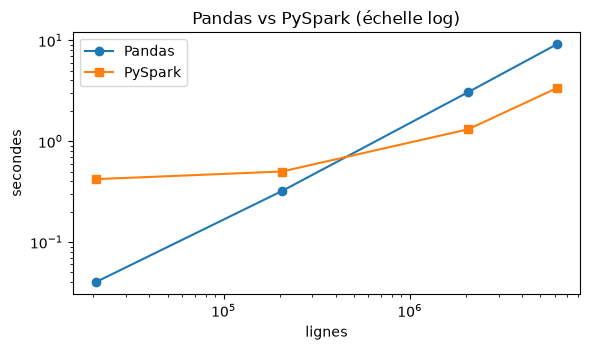

In [12]:
# Point de bascule : Pandas vs Spark sur des volumes croissants (réplication du fichier d'emprunts)
import tempfile, psutil, matplotlib.pyplot as plt
from pyspark.sql import functions as F
from spark_pipeline import SCHEMA

def pandas_job(path):
    df = pd.read_csv(path)
    for c in ['mode_emprunt', 'statut']:
        df[c] = df[c].str.strip().str.lower()
    df['valeur'] = pd.to_numeric(df['valeur_ouvrage_eur'].str.replace(' EUR', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')
    return df.groupby(['id_site', 'statut']).agg(n=('id_emprunt', 'size'), valeur=('valeur', 'mean')).shape[0], df

def spark_job(path):
    df = spark.read.csv(path, header=True, schema=SCHEMA)
    df = (df.withColumn('mode_emprunt', F.lower(F.trim('mode_emprunt'))).withColumn('statut', F.lower(F.trim('statut')))
            .withColumn('valeur', F.regexp_replace(F.regexp_replace('valeur_ouvrage_eur', ' EUR', ''), ',', '.').cast('double')))
    return df.groupBy('id_site', 'statut').agg(F.count('*').alias('n'), F.avg('valeur').alias('valeur')).count()

base = pd.read_csv(RAW_DIR / 'emprunts.csv')
bench_dir = Path(tempfile.mkdtemp())
rows = []
for k in [1, 10, 100, 300]:
    path = bench_dir / f'emprunts_x{k}.csv'
    pd.concat([base] * k, ignore_index=True).to_csv(path, index=False)
    (_, df_p), t_p = timed(lambda: pandas_job(path))
    mem_per_row = df_p.memory_usage(deep=True).sum() / len(df_p)
    del df_p
    _, t_s = timed(lambda: spark_job(str(path)))
    rows.append({'lignes': len(base) * k, 'pandas_s': round(t_p, 2), 'spark_s': round(t_s, 2), 'octets_par_ligne_pandas': round(mem_per_row)})
    path.unlink()
bench = pd.DataFrame(rows)
print(bench.to_string(index=False))

ram = psutil.virtual_memory().total
bytes_row = bench['octets_par_ligne_pandas'].iloc[-1]
limit_rows = int(0.5 * ram / bytes_row)          # 50 % de la RAM : marge pour les copies intermédiaires
print(f'\nRAM de cette machine : {ram/1e9:.1f} Go ; ~{bytes_row} octets/ligne en Pandas ;')
print(f'Pandas cesse de fonctionner autour de {limit_rows/1e6:.0f} M de lignes (en gardant 50 % de la RAM en marge)')

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(bench['lignes'], bench['pandas_s'], 'o-', label='Pandas'); ax.loglog(bench['lignes'], bench['spark_s'], 's-', label='PySpark')
ax.set_xlabel('lignes'); ax.set_ylabel('secondes'); ax.set_title('Pandas vs PySpark (échelle log)'); ax.legend(); fig.tight_layout()
fig.savefig(ROOT / 'figures' / 'benchmark.png', dpi=150); plt.show()
bench.to_csv(ROOT / 'results' / 'benchmark.csv', index=False)

**Pourquoi cette étape sur Spark, et pas la vitesse.** Le nettoyage est la seule étape purement ligne à ligne et sans état partagé : elle se partitionne sans réécriture. Sur nos 20 000 lignes, Pandas est ~10 fois plus rapide (0,04 s contre 0,38 s : Spark paie son démarrage). Les courbes se croisent vers 200 000 lignes ; à 2 M et plus, Spark devient plus rapide **sur cette machine multi-cœurs**, parce qu'il parallélise là où Pandas est mono-cœur, et non parce que Spark serait « plus rapide » en soi. Ce n'est donc pas la raison de la migration. Les raisons valables sont : (1) un volume qui dépasse la RAM (limite chiffrée ci-dessus), (2) le même code sur un cluster demain, (3) des données partitionnées sur disque dont on ne lit qu'une fraction. Aucune ne s'applique à 20 000 lignes : le composant démontre la portabilité et l'équivalence des résultats, pas un gain.

---
## 5. Résultat

In [13]:
from star import build_star, check_referential_integrity, export_star

star = build_star(analytic, clean)
print('Intégrité référentielle :'); check_referential_integrity(star)
assert len(star['fact_emprunt']) == len(clean['emprunts'])
print()
export_star(star, PROCESSED_DIR / 'star')
save_dataset(analytic, 'emprunts_analytiques')        # jeu final plat (une ligne par emprunt)
for name, df in star.items():
    print(f'{name:<14}', df.shape)

Intégrité référentielle :
  OK  fact_emprunt.cle_date     -> dim_date
  OK  fact_emprunt.id_adherent  -> dim_adherent
  OK  fact_emprunt.id_ouvrage   -> dim_ouvrage
  OK  fact_emprunt.id_site      -> dim_site

  écrit fact_emprunt.parquet (20383, 14)
  écrit dim_date.parquet (731, 9)
  écrit dim_adherent.parquet (2601, 7)
  écrit dim_ouvrage.parquet (421, 6)
  écrit dim_site.parquet (11, 6)
écrit : emprunts_analytiques.parquet (20383, 38)
fact_emprunt   (20383, 14)
dim_date       (731, 9)
dim_adherent   (2601, 7)
dim_ouvrage    (421, 6)
dim_site       (11, 6)


In [14]:
from scipy.stats import chi2_contingency
a_ = analytic.copy()
a_['perdu'] = a_['statut'] == 'perdu'
a_['site_reel'] = ~a_['est_site_technique']

def rate_table(by):
    t = a_.groupby(by).agg(emprunts=('id_emprunt', 'size'), taux_retard=('statut', lambda s: (s == 'en_retard').mean()),
                           taux_perdu=('perdu', 'mean'), valeur_perdue_eur=('valeur_ouvrage_eur', lambda s: s[a_.loc[s.index, 'perdu']].sum()))
    return t.round(3)

print('Par site :'); print(rate_table('id_site').to_string())
print('\nPar mode d\'emprunt :'); print(rate_table('mode_emprunt').to_string())
print('\nPar segment :'); print(rate_table('segment').to_string())

# Les écarts sont-ils significatifs ? (khi-deux statut x dimension)
for dim in ['id_site', 'mode_emprunt', 'segment', 'famille']:
    p = chi2_contingency(pd.crosstab(a_[dim], a_['statut']))[1]
    print(f'khi-deux statut x {dim:<13} p = {p:.3f}', '(écart significatif)' if p < 0.05 else '(pas d\'écart significatif)')

tot = a_.loc[a_['perdu'], 'valeur_ouvrage_eur'].sum(); tot_real = a_.loc[a_['perdu'] & a_['site_reel'], 'valeur_ouvrage_eur'].sum()
print(f'\nValeur des ouvrages perdus : {tot:,.0f} EUR (tous sites) | {tot_real:,.0f} EUR hors SIT99')
print(f"Taux d'emprunts à problème : {a_['est_probleme'].mean():.1%} (tous sites) | {a_.loc[a_['site_reel'], 'est_probleme'].mean():.1%} hors SIT99")

Par site :
         emprunts  taux_retard  taux_perdu  valeur_perdue_eur
id_site                                                      
SIT01        1860        0.172       0.182           17632.57
SIT02        1893        0.167       0.168           17096.12
SIT03        1804        0.163       0.167           16784.99
SIT04        1852        0.177       0.160           15758.68
SIT05        1852        0.180       0.162           16114.84
SIT06        1945        0.167       0.166           17701.56
SIT07        1843        0.169       0.149           15282.20
SIT08        1859        0.162       0.194           19221.03
SIT09        1819        0.180       0.168           16364.52
SIT10        1809        0.169       0.154           15646.26
SIT99        1847        0.168       0.182           18455.78

Par mode d'emprunt :
                      emprunts  taux_retard  taux_perdu  valeur_perdue_eur
mode_emprunt                                                              
portage    

In [15]:
# Moyenne ou médiane ? Ce que l'on publie engage.
ind = a_.groupby('famille').agg(valeur_moy=('valeur_ouvrage_eur', 'mean'), valeur_med=('valeur_ouvrage_eur', 'median'),
                                duree_moy=('duree_pret_jours', 'mean'), duree_med=('duree_pret_jours', 'median'))
ind['ecart_duree_pct'] = ((ind['duree_moy'] / ind['duree_med'] - 1) * 100).round(1)
ind['ecart_valeur_pct'] = ((ind['valeur_moy'] / ind['valeur_med'] - 1) * 100).round(1)
print(ind.round(2).to_string())

num = ['duree_pret_jours', 'nb_prolongations', 'valeur_ouvrage_eur', 'anciennete_adherent_jours', 'age', 'valeur_par_jour']
pear, spear = a_[num].corr('pearson'), a_[num].corr('spearman')
print('\nCorrélations les plus fortes (|Pearson| hors diagonale) :')
pairs = pear.where(np.triu(np.ones(pear.shape, bool), 1)).stack().abs().sort_values(ascending=False).head(3)
for (c1, c2), v in pairs.items():
    print(f'  {c1} x {c2} : Pearson {pear.loc[c1,c2]:.2f} | Spearman {spear.loc[c1,c2]:.2f}')
print('-> valeur_par_jour = valeur / durée : corrélation tautologique avec ses deux composantes, à ne pas interpréter.')

           valeur_moy  valeur_med  duree_moy  duree_med  ecart_duree_pct  ecart_valeur_pct
famille                                                                                   
Famille A       53.15       52.47      24.93       24.0              3.9               1.3
Famille B       53.41       52.57      24.64       24.0              2.7               1.6
Famille C       53.43       52.19      25.24       24.0              5.2               2.4
Famille D       52.36       51.41      24.97       24.0              4.1               1.8
Famille E       53.30       52.10      25.01       24.0              4.2               2.3
Inconnu         58.89       61.43      25.85       24.0              7.7              -4.1



Corrélations les plus fortes (|Pearson| hors diagonale) :
  valeur_ouvrage_eur x valeur_par_jour : Pearson 0.64 | Spearman 0.78
  duree_pret_jours x valeur_par_jour : Pearson -0.43 | Spearman -0.57
  valeur_ouvrage_eur x anciennete_adherent_jours : Pearson 0.02 | Spearman 0.01
-> valeur_par_jour = valeur / durée : corrélation tautologique avec ses deux composantes, à ne pas interpréter.


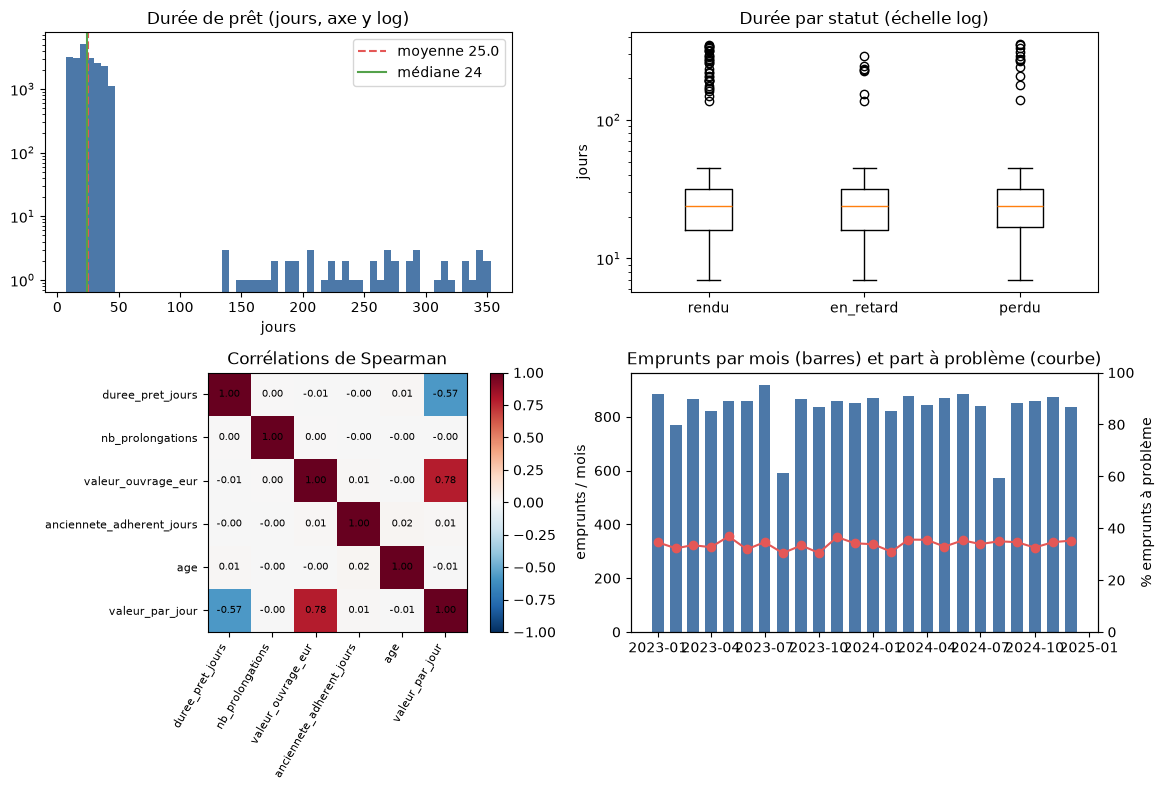

In [16]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]                                       # 1. distribution (axe y log : sinon les extrêmes disparaissent)
ax.hist(a_['duree_pret_jours'], bins=60, color='#4C78A8'); ax.set_yscale('log')
ax.axvline(a_['duree_pret_jours'].mean(), color='#E45756', ls='--', label=f"moyenne {a_['duree_pret_jours'].mean():.1f}")
ax.axvline(a_['duree_pret_jours'].median(), color='#54A24B', ls='-', label=f"médiane {a_['duree_pret_jours'].median():.0f}")
ax.set_title('Durée de prêt (jours, axe y log)'); ax.set_xlabel('jours'); ax.legend()

ax = axes[0, 1]                                       # 2. boxplot par statut, échelle log
order = ['rendu', 'en_retard', 'perdu']
ax.boxplot([a_.loc[a_['statut'] == s, 'duree_pret_jours'] for s in order], tick_labels=order); ax.set_yscale('log')
ax.set_title('Durée par statut (échelle log)'); ax.set_ylabel('jours')

ax = axes[1, 0]                                       # 3. corrélations de Spearman
im = ax.imshow(spear, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{spear.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
ax.set_title('Corrélations de Spearman'); fig.colorbar(im, ax=ax, fraction=0.046)

ax = axes[1, 1]                                       # 4. série temporelle sur une plage mensuelle continue
monthly = a_.dropna(subset=['date_emprunt']).set_index('date_emprunt').resample('MS').agg(
    emprunts=('id_emprunt', 'size'), taux=('est_probleme', 'mean'))
ax.bar(monthly.index, monthly['emprunts'], width=20, color='#4C78A8'); ax.set_ylim(0); ax.set_ylabel('emprunts / mois')
ax2 = ax.twinx(); ax2.plot(monthly.index, monthly['taux'] * 100, color='#E45756', marker='o'); ax2.set_ylim(0, 100)
ax2.set_ylabel('% emprunts à problème'); ax.set_title('Emprunts par mois (barres) et part à problème (courbe)')
fig.tight_layout(); fig.savefig(ROOT / 'figures' / 'planche.png', dpi=150); plt.show()

In [17]:
# Contrôles de cohérence du jeu final + export des indicateurs clés
fact = star['fact_emprunt']
assert fact['id_emprunt'].is_unique and fact.isna().sum().sum() == 0
assert (fact['duree_pret_jours'] > 0).all() and (fact['valeur_ouvrage_eur'] > 0).all()
assert np.isclose(fact['valeur_perdue_eur'].sum(), tot)
print('Jeu final cohérent :', fact.shape, '| période', analytic['date_emprunt'].min().date(), '->', analytic['date_emprunt'].max().date())

metrics = {
    'lignes_brutes': int(len(raw['emprunts'])), 'lignes_finales': int(len(fact)),
    'taux_retard': round(float((a_['statut'] == 'en_retard').mean()), 4), 'taux_perdu': round(float(a_['perdu'].mean()), 4),
    'taux_probleme': round(float(a_['est_probleme'].mean()), 4), 'valeur_perdue_eur': round(float(tot), 2),
    'valeur_perdue_hors_sit99_eur': round(float(tot_real), 2),
    'p_site': round(float(chi2_contingency(pd.crosstab(a_['id_site'], a_['statut']))[1]), 4),
    'p_mode': round(float(chi2_contingency(pd.crosstab(a_['mode_emprunt'], a_['statut']))[1]), 4),
    'p_segment': round(float(chi2_contingency(pd.crosstab(a_['segment'], a_['statut']))[1]), 4),
    'p_famille': round(float(chi2_contingency(pd.crosstab(a_['famille'], a_['statut']))[1]), 4),
    'colonnes_encodees': int(X_train.shape[1]), 'emprunt_avant_adhesion': int(analytic['emprunt_avant_adhesion'].sum()),
    'ram_go': round(ram / 1e9, 1), 'limite_pandas_millions_lignes': round(limit_rows / 1e6),
    'benchmark': bench.to_dict('records'),
}
(ROOT / 'results' / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2))
metrics

Jeu final cohérent : (20383, 14) | période 2023-01-01 -> 2024-12-30


{'lignes_brutes': 20563,
 'lignes_finales': 20383,
 'taux_retard': 0.1703,
 'taux_perdu': 0.1683,
 'taux_probleme': 0.3386,
 'valeur_perdue_eur': 186058.55,
 'valeur_perdue_hors_sit99_eur': 167602.77,
 'p_site': 0.1123,
 'p_mode': 0.7681,
 'p_segment': 0.4023,
 'p_famille': 0.4255,
 'colonnes_encodees': 23,
 'emprunt_avant_adhesion': 1996,
 'ram_go': 8.4,
 'limite_pandas_millions_lignes': 28,
 'benchmark': [{'lignes': 20563,
   'pandas_s': 0.04,
   'spark_s': 0.42,
   'octets_par_ligne_pandas': 153},
  {'lignes': 205630,
   'pandas_s': 0.32,
   'spark_s': 0.5,
   'octets_par_ligne_pandas': 153},
  {'lignes': 2056300,
   'pandas_s': 3.06,
   'spark_s': 1.31,
   'octets_par_ligne_pandas': 153},
  {'lignes': 6168900,
   'pandas_s': 9.14,
   'spark_s': 3.36,
   'octets_par_ligne_pandas': 153}]}

### Limites assumées

1. **Données synthétiques, écarts faibles.** Les taux de retard et de perte sont quasi uniformes entre sites, modes, segments et familles (tests du khi-deux ci-dessus) : on ne peut pas désigner un site ou un profil « coupable ». Une conclusion plus forte serait fabriquée.
2. **Incohérence temporelle non corrigée.** ~10 % des emprunts datent d'avant la création de l'adhésion (`emprunt_avant_adhesion`). Signalée, pas corrigée : on ne sait pas quelle date est fausse.
3. **Imputations et exclusions partielles.** 9 % des durées et 5 % des âges sont imputés (médiane) : indicateurs `duree_imputee` / `age_imputee` fournis. 2 % des emprunts n'ont pas de date (clé « inconnue », absents des séries temporelles). Deux doublons d'adhérents (âge inutilisable) n'ont pas pu être fusionnés. Le statut du site SIT99 reste à confirmer auprès du propriétaire des données.

In [18]:
checks = {
    'requirements.txt présent': (ROOT / 'requirements.txt').exists(),
    'README.md présent': (ROOT / 'README.md').exists(),
    'dossier src/ non vide': (ROOT / 'src').exists() and any((ROOT / 'src').glob('*.py')),
    'jeu final produit': (any(PROCESSED_DIR.glob('*.parquet')) or any(PROCESSED_DIR.glob('*.csv'))),
    'note méthodologique': any(ROOT.glob('note_methodologique.*')),
    'support de soutenance': any(ROOT.glob('soutenance.*')),
}
width = max(len(label) for label in checks)
for label, is_ok in checks.items():
    print(f"{label:<{width}}  {'OK' if is_ok else 'MANQUANT'}")
print('\nRendu complet.' if all(checks.values()) else '\nIl manque des éléments listés ci-dessus.')

requirements.txt présent  OK
README.md présent         OK
dossier src/ non vide     OK
jeu final produit         OK
note méthodologique       OK
support de soutenance     OK

Rendu complet.


---
## 7. Préparation aux questions

1. **Pourquoi avoir imputé la durée par la médiane ?** La durée est asymétrique (extrêmes jusqu'à 353 j) : la moyenne (25,0) serait tirée vers le haut, la médiane (24) décrit le prêt typique. L'écart est faible ici, mais la médiane ne bouge pas si de nouveaux extrêmes arrivent. Et l'indicateur `duree_imputee` garde la trace.
2. **Lignes écartées ?** Seuls 180 doublons stricts (même `id_emprunt`, toutes colonnes égales : un prêt ne peut pas exister deux fois) et 49 adhérents fusionnés sont supprimés. Aucune valeur « atypique » n'est supprimée : les durées > 90 j sont conservées et signalées.
3. **Colonnes de l'encodage ?** 23 colonnes (voir cellule) : 5 numériques + 17 one-hot + 1 fréquence. Cardinalité maximale 6, donc aucune explosion de dimension.
4. **Limite de Pandas ?** Voir le calcul du benchmark : ~octets/ligne × lignes ≈ 50 % de la RAM. Au-delà, il faut Spark (partitionnement) ou un traitement par blocs.
5. **Nouveau fichier au même format ?** Placer les CSV dans `data/raw/`, relancer `python src/pipeline.py` : les fonctions sont idempotentes et `parse_dates` / `safe_merge` / `check_referential_integrity` échouent bruyamment si le format change.
6. **La ligne qui traite un cas particulier ?** `out['id_adherent'].replace(id_map)` dans `clean_emprunts` : remappe les 11 emprunts des adhérents ADH99xxx fusionnés. Ou `parse_price_eur` pour « 90,06 EUR ».
7. **Principale limite ?** Des écarts quasi nuls entre groupes (khi-deux non significatifs) et ~10 % d'emprunts antérieurs à l'adhésion.